1. WAP to enhance the input image using log transformation.Assume c=1.
2. WAP to enhance the inout image using power/law gamma transform. Assume c=1, and input value of gamma from the user.
3. WAP to enhance the input image using Intensity level slicing (Contrast stretching). The input range of intensity values and the desired range of intensity values in the output image are obtained from the user. (Example: The input range of intensity values from 80 to 120 is stretched to 50-150 in the output image.)




In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import os

print(os.listdir())

['.config', 'input.jpg', 'sample_data']


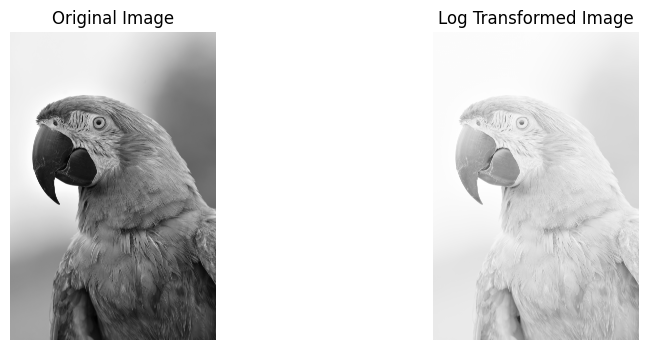

Log transformation completed successfully!


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("input.jpg", cv2.IMREAD_GRAYSCALE)

# Check if image was loaded
if img is None:
    print("Error: Image not found!")
else:
    # Convert image to float
    img_float = img.astype(np.float32)

    # Log transformation
    # s = c * log(1 + r), where c = 1
    log_img = np.log(1 + img_float)

    # Manually normalize to 0-255
    log_img = (log_img - log_img.min()) / (log_img.max() - log_img.min())
    log_img = log_img * 255

    # Convert to uint8
    log_img = log_img.astype(np.uint8)

    # Display original and transformed images
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(log_img, cmap="gray")
    plt.title("Log Transformed Image")
    plt.axis("off")

    plt.show()

    # Save output
    cv2.imwrite("log_transformed.jpg", log_img)

    print("Log transformation completed successfully!")

Enter the value of gamma: 0.5


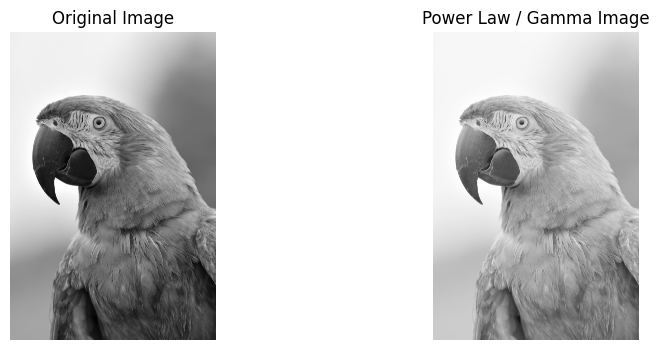

Gamma transformation completed successfully!


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read the image
img = cv2.imread("input.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
else:
    # Take gamma value from user
    gamma = float(input("Enter the value of gamma: "))

    # Normalize image to 0-1
    normalized = img.astype(np.float32) / 255.0

    # Power law transformation
    # s = c * r^gamma
    # c = 1
    gamma_img = np.power(normalized, gamma)

    # Convert back to 0-255
    gamma_img = (gamma_img * 255).astype(np.uint8)

    # Display images
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(gamma_img, cmap="gray")
    plt.title("Power Law / Gamma Image")
    plt.axis("off")

    plt.show()

    # Save output
    cv2.imwrite("gamma_transformed.jpg", gamma_img)

    print("Gamma transformation completed successfully!")

Enter input minimum intensity: 80
Enter input maximum intensity: 120
Enter output minimum intensity: 50
Enter output maximum intensity: 150


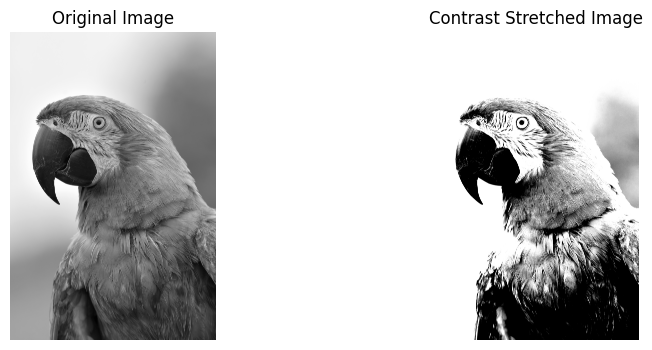

Contrast stretching completed successfully!


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("input.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found!")
else:
    # Get input intensity range
    r_min = int(input("Enter input minimum intensity: "))
    r_max = int(input("Enter input maximum intensity: "))

    # Get desired output range
    s_min = int(input("Enter output minimum intensity: "))
    s_max = int(input("Enter output maximum intensity: "))

    # Convert image to float
    img_float = img.astype(np.float32)

    # Contrast stretching formula
    stretched = ((img_float - r_min) * (s_max - s_min) /
                 (r_max - r_min)) + s_min

    # Keep values within desired output range
    stretched = np.clip(stretched, s_min, s_max)

    # Convert to uint8
    stretched = stretched.astype(np.uint8)

    # Display
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(stretched, cmap="gray")
    plt.title("Contrast Stretched Image")
    plt.axis("off")

    plt.show()

    # Save result
    cv2.imwrite("contrast_stretched.jpg", stretched)

    print("Contrast stretching completed successfully!")